<a href="https://colab.research.google.com/github/yavanikaharunesh-sys/COMPUTER-VISION-slot-C-Yavanika/blob/main/Experiment_25_Object_Recognition_Using_MobileNetV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Greater Flamingo in Calm Waters.png to Greater Flamingo in Calm Waters.png


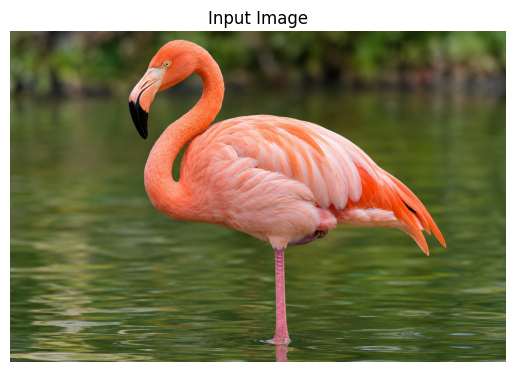

flamingo : 92.93 %
black_swan : 0.27 %
European_gallinule : 0.12 %
goose : 0.09 %
stinkhorn : 0.08 %


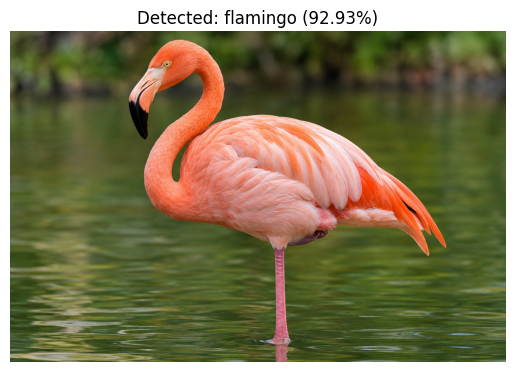

In [2]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions

uploaded = files.upload()
image = cv2.imread(list(uploaded.keys())[0])

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input Image")
plt.axis("off")
plt.show()

model = MobileNetV2(weights="imagenet")

img = cv2.resize(image, (224, 224))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = np.expand_dims(img, axis=0)
img = preprocess_input(img)

predictions = model.predict(img, verbose=0)
results = decode_predictions(predictions, top=5)[0]

for _, label, confidence in results:
    print(label, ":", round(confidence * 100, 2), "%")

best_label = results[0][1]
confidence = results[0][2] * 100

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"Detected: {best_label} ({confidence:.2f}%)")
plt.axis("off")
plt.show()